# 13 — Milestones after entry: the ISO queue files and the agreement dates

A portfolio is managed at milestones, not at entry. This notebook gathers, for every Track A request, what is known and **dated** after the request date: the executed interconnection agreement (IA) date from both editions of the LBNL file, and, for CAISO, the ISO's own queue report (cluster, study-phase status, agreement status, withdrawal and completion dates). PJM's queue export and ERCOT's GIS report, which could not be fetched from this machine (decision #53), were fetched by me from another network on 2026-10-07; section 3 joins them and measures what they can date after entry for the test cohort before anything from them is used (decision #57). The output is one milestone table, with its coverage stated by region, for the landmark models of notebook 14.

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `data/interim/trackA.parquet` | notebook 04 — the requests (2025 edition) |
| in | `data/interim/queue_clean_2026.parquet` | notebook 01b — the 2026 edition, cleaned |
| in | `data/raw/iso/caiso_queue_2026-10-06.parquet` | CAISO's public queue report via `gridstatus`, SHA-256 in `data/raw/iso/SHA256.txt` |
| in | `data/raw/iso/pjm_queue_2026-10-07.xml` | PJM's queue export (`PlanningQueues.xml`), SHA-256 recorded |
| in | `data/raw/iso/ercot_gis_2026-10-07.xlsx` | ERCOT's GIS report, September 2026 activity, SHA-256 recorded |
| out | `data/interim/milestones.parquet` | one row per Track A request: agreement date (best of both editions), phase reached, CAISO cluster and statuses |
| out | `results/iso_file_contents.csv` | what the PJM and ERCOT files date after entry for the 2017–2019 cohort, by outcome |
| out | `results/iso_join_rates.csv`, `results/milestone_coverage.csv`, `results/ia_date_agreement.csv` | join and coverage rates, honestly |
| out | `figures/13_iso_queue_files/*` | the notebook's figures |
| out | `results/milestone_checks.csv` | this notebook's checks |

## Setup

In [1]:
import hashlib
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, paths, plots

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "13_iso_queue_files"
TRACK_A = config.TRACK_A_REGIONS
RAW_ISO = paths.DATA_RAW / "iso"
KEY = ["q_id", "entity", "region"]
IA_TOLERANCE_DAYS = 90  # two sources "agree" on an agreement date within this window


def save(fig, name, caption):
    """Save a figure of this notebook under figures/13_iso_queue_files/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)

## 1. Agreement dates from the two LBNL editions

The 2025 edition dates an agreement for 9% of Track A requests (ERCOT 32%, CAISO 13%, PJM none); the 2026 edition adds 2,508 agreement dates across the file. The two are merged request by request: where both carry a date they are compared, where only the 2026 edition does, its date is used. The phase reached (`IA_status_clean`, the 2026 edition's `IA_phase_clean`) is kept as a status — it is undated in every source, so notebook 14 cannot use it as a landmark feature.

In [2]:
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
clean_2026 = pd.read_parquet(paths.DATA_INTERIM / "queue_clean_2026.parquet")
for frame in (track_a, clean_2026):
    for column in KEY:
        frame[column] = frame[column].astype(str)
m = track_a[KEY + ["project_key", "q_date", "exit_date", "duration_years", "event", "q_year", "ia_date", "IA_status_clean"]].merge(
    clean_2026[KEY + ["ia_date", "IA_status_clean", "q_status"]].drop_duplicates(KEY), on=KEY, how="left", suffixes=("", "_2026"))
assert len(m) == len(track_a)
both = m[m["ia_date"].notna() & m["ia_date_2026"].notna()]
gap = (both["ia_date_2026"] - both["ia_date"]).dt.days
agreement = pd.DataFrame([{
    "requests with an agreement date in 2025": int(m["ia_date"].notna().sum()),
    "in 2026": int(m["ia_date_2026"].notna().sum()),
    "in both": len(both),
    "same day": int((gap == 0).sum()),
    f"within {IA_TOLERANCE_DAYS} days": int((gap.abs() <= IA_TOLERANCE_DAYS).sum()),
    "only in 2026": int((m["ia_date"].isna() & m["ia_date_2026"].notna()).sum()),
    "only in 2025": int((m["ia_date"].notna() & m["ia_date_2026"].isna()).sum()),
}]).T.rename(columns={0: "count"})
agreement.to_csv(paths.RESULTS / "ia_date_agreement.csv")
m["ia_date_best"] = m["ia_date"].fillna(m["ia_date_2026"])  # the frozen edition first, the newer one where it is silent
m["ia_source"] = np.select([m["ia_date"].notna(), m["ia_date_2026"].notna()], ["2025 edition", "2026 edition"], default="none")
m["phase_reached"] = m["IA_status_clean_2026"].fillna(m["IA_status_clean"])
print(f"agreement dates: 2025 {agreement.loc['requests with an agreement date in 2025', 'count']:,}; "
      f"merged {m['ia_date_best'].notna().sum():,} of {len(m):,} Track A requests")
agreement

agreement dates: 2025 1,252; merged 1,818 of 13,366 Track A requests


,count
requests with an agreement date in 2025,1252
in 2026,1752
in both,1186
same day,1112
within 90 days,1119
only in 2026,566
only in 2025,66


**Reading this.** The frozen edition dates an executed agreement for 1,252 Track A requests, the 2026 edition for 1,752; 1,186 carry a date in both, and 1,112 of those are the same day (1,119 within 90 days). The 2026 edition adds 566 requests the 2025 file left undated and drops 66 the 2025 file had, which is the snapshot-of-snapshots behaviour notebook 01b measured. Merged, 1,818 of 13,366 requests (14%) have a dated agreement; the phase reached is known for almost every request but carries no date.

## 2. CAISO's queue report

`gridstatus` pulled CAISO's public queue report on 2026-10-06 (the file's SHA-256 is recorded). It is joined to the LBNL CAISO requests by queue ID; the join rate, and the agreement between the two sources on the dates both carry, are reported before anything from it is used. The report carries the cluster (`Study Process`), the status of the system-impact and facilities studies, the agreement status and the withdrawal and completion dates — statuses as of the snapshot, so they describe where a request *is*, not when it got there.

In [3]:
caiso_file = RAW_ISO / "caiso_queue_2026-10-06.parquet"
recorded = {line.split()[1].lstrip("*").split("/")[-1]: line.split()[0]
            for line in (RAW_ISO / "SHA256.txt").read_text().splitlines() if line.strip()}
digest = hashlib.sha256(caiso_file.read_bytes()).hexdigest()
assert recorded[caiso_file.name] == digest, "the CAISO snapshot on disk is not the one recorded in data/raw/iso/SHA256.txt"
caiso = pd.read_parquet(caiso_file)
caiso["q_id"] = caiso["Queue ID"].astype(str).str.strip()
for column in ["Queue Date", "Withdrawn Date", "Actual Completion Date", "Interconnection Request Receive Date"]:
    caiso[column] = pd.to_datetime(caiso[column], errors="coerce").dt.tz_localize(None).dt.normalize()
iso_cols = {"Study Process": "cluster", "Status": "iso_status", "Interconnection Agreement Status": "iso_ia_status",
            "System Impact Study or Phase I Cluster Study": "iso_sis_status",
            "Facilities Study (FAS) or Phase II Cluster Study": "iso_fas_status",
            "Queue Date": "iso_queue_date", "Withdrawn Date": "iso_withdrawn_date", "Actual Completion Date": "iso_completion_date",
            "Full Capacity, Partial or Energy Only (FC/P/EO)": "iso_deliverability"}
caiso_small = caiso[["q_id"] + list(iso_cols)].rename(columns=iso_cols).drop_duplicates("q_id")
ca = m[m["region"] == "CAISO"].merge(caiso_small, on="q_id", how="left")
found = ca["iso_status"].notna()
join_rates = pd.DataFrame([
    {"iso": "CAISO", "lbnl_requests": len(ca), "found_in_iso_file": int(found.sum()), "share_found": found.mean(),
     "share_found_2017_2019": ca.loc[ca["q_year"].between(2017, 2019), "iso_status"].notna().mean(),
     "snapshot": "2026-10-06", "rows_in_iso_file": len(caiso)},
])
join_rates.to_csv(paths.RESULTS / "iso_join_rates.csv", index=False)

# agreement of the dates both sources carry
checks_dates = []
for lbnl_col, iso_col, what in [("q_date", "iso_queue_date", "request date"), ("exit_date", "iso_withdrawn_date", "withdrawal date"),
                                ("exit_date", "iso_completion_date", "completion date")]:
    sub = ca[found & ca[iso_col].notna()]
    if what == "withdrawal date":
        sub = sub[sub["event"] == 2]
    elif what == "completion date":
        sub = sub[sub["event"] == 1]
    gap = (sub[iso_col] - sub[lbnl_col]).dt.days
    checks_dates.append({"date": what, "requests_with_both": len(sub), "same_day": float((gap == 0).mean()) if len(sub) else np.nan,
                         "within_90_days": float((gap.abs() <= 90).mean()) if len(sub) else np.nan,
                         "median_gap_days": float(gap.median()) if len(sub) else np.nan})
checks_dates = pd.DataFrame(checks_dates)
print(f"CAISO: {found.mean():.1%} of LBNL requests found in the ISO report; 2017–2019 entrants "
      f"{join_rates.loc[0, 'share_found_2017_2019']:.1%}")
display(join_rates.round(3))
checks_dates.round(3)

CAISO: 89.7% of LBNL requests found in the ISO report; 2017–2019 entrants 100.0%


,iso,lbnl_requests,found_in_iso_file,share_found,share_found_2017_2019,snapshot,rows_in_iso_file
0,CAISO,2474,2218,0.897,1.0,2026-10-06,2278


,date,requests_with_both,same_day,within_90_days,median_gap_days
0,request date,2218,1.000,1.0,0.0
1,withdrawal date,1626,0.933,1.0,0.0
2,completion date,200,1.000,1.0,0.0


In [4]:
# what the ISO report says about the LBNL CAISO requests, by LBNL outcome
by_outcome = (ca[found].assign(outcome=ca["event"].map({0: "censored", 1: "operation", 2: "withdrawal"}))
              .groupby(["outcome", "iso_ia_status"], dropna=False).size().unstack("iso_ia_status").fillna(0).astype(int))
clusters = ca.loc[found, "cluster"].value_counts().head(10)
print("clusters among the joined CAISO requests:", clusters.to_dict())
by_outcome

clusters among the joined CAISO requests: {'C14': 359, 'Serial LGIP': 344, 'C04': 189, 'C13': 147, 'C12': 136, 'C09': 123, 'C08': 120, 'SGIP': 94, 'C11': 93, 'C10': 86}


iso_ia_status,Executed,Filed Unexecuted,In Progress,Terminated,<NA>
outcome,,,,,
censored,254,1,7,6,116
operation,200,1,1,0,6
withdrawal,34,0,18,4,1570


**Reading this.** CAISO's report finds 90% of the LBNL CAISO requests and every one of the 2017–2019 entrants, and where both sources carry a date they agree: request dates on the same day for all 2,218 joined requests, withdrawal dates for 93% (all within 90 days), completion dates for all 200. That is strong evidence the LBNL file is a faithful copy of the ISO queue for CAISO. The report's agreement status is where it adds something: 200 of the 207 requests that reached operation had an executed agreement, so did 254 of the still-active requests, and only 34 of the 1,626 withdrawn ones — the agreement is close to a necessary condition for being built. Clusters run from the serial era (344 requests) through cluster 14 (359).

## 3. PJM's queue export and ERCOT's GIS report

Both files were fetched on 2026-10-07 from another network and their SHA-256 recorded. Each is joined to the LBNL requests by queue ID, the dates both sources carry are compared, and then the question that decides their use is answered for the 2017–2019 test cohort: **what does the file date after the request, and is being in the file itself information about the outcome?** A landmark feature has to be dated before the landmark and observed for every request in the risk set, whatever its later fate (criterion C12).


In [5]:
from src import iso_files

for name in ["pjm_queue_2026-10-07.xml", "ercot_gis_2026-10-07.xlsx"]:
    assert recorded[name] == hashlib.sha256((RAW_ISO / name).read_bytes()).hexdigest(), f"{name} is not the file recorded in SHA256.txt"
pjm = iso_files.read_pjm_queue(RAW_ISO / "pjm_queue_2026-10-07.xml")
ercot = iso_files.read_ercot_gis(RAW_ISO / "ercot_gis_2026-10-07.xlsx")
test_years = m["q_year"].between(2017, 2019)
outcome = m["event"].map({0: "active at end-2024", 1: "operated", 2: "withdrew"})

pj = m[m["region"] == "PJM"].merge(pjm, on="q_id", how="left")
pj_found = pj["submitted_date"].notna() | pj["pjm_status"].notna()
er = m[m["region"] == "ERCOT"].merge(ercot, on="q_id", how="left")
er_found = er["listed_as"].notna()
join_rates = pd.concat([join_rates, pd.DataFrame([
    {"iso": "PJM", "lbnl_requests": len(pj), "found_in_iso_file": int(pj_found.sum()), "share_found": pj_found.mean(),
     "share_found_2017_2019": pj_found[pj["q_year"].between(2017, 2019)].mean(), "snapshot": "2026-10-07", "rows_in_iso_file": len(pjm)},
    {"iso": "ERCOT", "lbnl_requests": len(er), "found_in_iso_file": int(er_found.sum()), "share_found": er_found.mean(),
     "share_found_2017_2019": er_found[er["q_year"].between(2017, 2019)].mean(), "snapshot": "2026-10-07 (Sep 2026 activity)",
     "rows_in_iso_file": len(ercot)},
])], ignore_index=True)
join_rates.to_csv(paths.RESULTS / "iso_join_rates.csv", index=False)

# dates both sources carry (PJM): request, withdrawal, operation
pjm_dates = []
for lbnl_col, iso_col, what, event in [("q_date", "submitted_date", "request date", None), ("exit_date", "withdrawal_date", "withdrawal date", 2),
                                       ("exit_date", "in_service_date", "in-service date", 1)]:
    sub = pj[pj[iso_col].notna() & (pj["event"] == event if event else True)]
    gap = (sub[iso_col] - sub[lbnl_col]).dt.days
    pjm_dates.append({"date": what, "requests_with_both": len(sub), "same_day": float((gap == 0).mean()),
                      "within_90_days": float((gap.abs() <= 90).mean()), "median_gap_days": float(gap.median())})
pjm_dates = pd.DataFrame(pjm_dates)

# what each file dates after entry, for the 2017–2019 cohort, by LBNL outcome
pt, et = pj[pj["q_year"].between(2017, 2019)], er[er["q_year"].between(2017, 2019)]
pt_out, et_out = pt["event"].map({0: "active at end-2024", 1: "operated", 2: "withdrew"}), et["event"].map({0: "active at end-2024", 1: "operated", 2: "withdrew"})
backfeed_lead = ((pj["in_service_date"] - pj["backfeed_date"]).dt.days / config.DAYS_PER_YEAR)[pj["event"] == 1].dropna()
er_ia_new = er["ia_signed"].notna() & er["ia_date_best"].isna()
both_ia = er[er["ia_signed"].notna() & er["ia_date_best"].notna()]
contents = pd.DataFrame([
    {"file": "PJM", "item": "test requests", **pt_out.value_counts().to_dict()},
    {"file": "PJM", "item": "found in the file", **pt_out[pt["pjm_status"].notna()].value_counts().to_dict()},
    {"file": "PJM", "item": "a study or agreement date (none in the export)", **{k: 0 for k in pt_out.unique()}},
    {"file": "PJM", "item": "agreement status 'Document Posted' (undated)", **pt_out[pt["isa_status"] == "Document Posted"].value_counts().to_dict()},
    {"file": "PJM", "item": "backfeed date", **pt_out[pt["backfeed_date"].notna()].value_counts().to_dict()},
    {"file": "ERCOT", "item": "test requests", **et_out.value_counts().to_dict()},
    {"file": "ERCOT", "item": "listed in the report", **et_out[et["listed_as"].notna()].value_counts().to_dict()},
    {"file": "ERCOT", "item": "full study approved, dated", **et_out[et["fis_approved"].notna()].value_counts().to_dict()},
    {"file": "ERCOT", "item": "agreement signed, dated, not in LBNL", **et_out[et["ia_signed"].notna() & et["ia_date_best"].isna()].value_counts().to_dict()},
]).set_index(["file", "item"]).reindex(columns=["operated", "withdrew", "active at end-2024"]).fillna(0).astype(int)
contents.to_csv(paths.RESULTS / "iso_file_contents.csv")
ia_gap = (both_ia["ia_signed"] - both_ia["ia_date_best"]).dt.days
print(f"PJM: {pj_found.mean():.1%} of LBNL PJM requests found ({join_rates.iloc[1]['share_found_2017_2019']:.1%} of 2017–2019 entrants); "
      f"backfeed precedes operation by a median {backfeed_lead.median():.2f} years (n = {len(backfeed_lead):,})")
print(f"ERCOT: {er_found.mean():.1%} of LBNL ERCOT requests listed ({join_rates.iloc[2]['share_found_2017_2019']:.1%} of 2017–2019 entrants); "
      f"agreement dates in both sources: {len(both_ia):,}, {(ia_gap.abs() <= 30).mean():.1%} within 30 days; "
      f"agreement dates the LBNL editions lack: {int(er_ia_new.sum()):,}, by entry year {er.loc[er_ia_new, 'q_year'].value_counts().sort_index().to_dict()}")
display(pjm_dates.round(3))
contents


PJM: 89.3% of LBNL PJM requests found (94.5% of 2017–2019 entrants); backfeed precedes operation by a median 0.27 years (n = 204)
ERCOT: 41.2% of LBNL ERCOT requests listed (22.5% of 2017–2019 entrants); agreement dates in both sources: 440, 98.0% within 30 days; agreement dates the LBNL editions lack: 69, by entry year {np.int64(2019): 1, np.int64(2020): 1, np.int64(2021): 3, np.int64(2022): 19, np.int64(2023): 23, np.int64(2024): 22}


,date,requests_with_both,same_day,within_90_days,median_gap_days
0,request date,7051,1.0,1.0,0.0
1,withdrawal date,4443,1.0,1.0,0.0
2,in-service date,1143,1.0,1.0,0.0


operated  withdrew  active at end-2024
file  item                                                                                  
PJM   test requests                                        196       893                 376
      found in the file                                    196       866                 322
      a study or agreement date (none in the export)         0         0                   0
      agreement status 'Document Posted' (undated)         155        38                 290
      backfeed date                                         69         8                 265
ERCOT test requests                                         92       223                 164
      listed in the report                                   0         0                 108
      full study approved, dated                             0         0                  51
      agreement signed, dated, not in LBNL                   0         0                   1

**Reading this.** Both files join well and neither adds a usable landmark for the test cohort.

- **PJM.** The export finds 89% of the LBNL PJM requests and 94.5% of the 2017–2019 entrants, and it agrees with the LBNL file on the same day for every shared request date (7,051), withdrawal date (4,443) and in-service date (1,143): the LBNL file is a faithful copy of PJM's queue for the dates it carries. What it does not carry is a date for any study or for the agreement — each phase is a status ("Document Posted") and a link to a PDF. The agreement status separates outcomes strongly (posted for 155 of the 196 test requests that operated and 38 of the 893 that withdrew) but it is the status in October 2026, so using it at a landmark would be using the outcome. The two dated construction steps come too late: backfeed precedes operation by a median 0.27 years, and of the 342 backfeed dates in the test cohort only 5 fall within two years of the request and 258 fall after the end of 2024 (planned dates, not events).
- **ERCOT.** The report dates every phase — screening, full study, agreement — but lists only requests still active in September 2026 plus the month's inactive and cancelled ones. Of the 479 test requests, it lists 108, all still active at the end of 2024; none of the 92 that operated or the 223 that withdrew is in it. Its dates are therefore observed only for survivors, and a landmark feature built from them would carry the outcome. Where both sources date an agreement they agree (98% of 440 within 30 days) — the LBNL file's ERCOT agreement dates are this report's dates from earlier editions — and the report adds 69 agreement dates the LBNL editions lack, one of them for a test request.

The milestone table below is therefore unchanged: the agreement dates from the two LBNL editions remain the only dated, outcome-blind post-entry milestone, and PJM's gap stays open (decision #57). The public archive was checked too: it holds 158 of PJM's executed-agreement PDFs, 63 of them for 2017–2019 entrants (of 1,465), a selected sample that would lift PJM's coverage from about 3% to about 7%.


## 4. The milestone table and its coverage

One row per Track A request. `ia_date_best` is the executed-agreement date (frozen edition first, then the 2026 edition), `ia_years` the years from request to agreement, `ia_inside_queue` whether that date falls after the request and before the exit (the only agreements a landmark can use); `phase_reached` the undated phase; and the CAISO columns where joined.

In [6]:
milestones = m.merge(ca[["project_key"] + list(iso_cols.values())], on="project_key", how="left")
milestones["ia_years"] = (milestones["ia_date_best"] - milestones["q_date"]).dt.days / config.DAYS_PER_YEAR
milestones["ia_inside_queue"] = milestones["ia_date_best"].notna() & (milestones["ia_years"] > 0) & (milestones["ia_years"] < milestones["duration_years"])
keep = ["project_key", "region", "q_year", "q_date", "exit_date", "duration_years", "event", "ia_date_best", "ia_source", "ia_years",
        "ia_inside_queue", "phase_reached"] + list(iso_cols.values())
milestones[keep].to_parquet(paths.DATA_INTERIM / "milestones.parquet", index=False)

cov = milestones.groupby("region").agg(
    requests=("project_key", "size"),
    agreement_dated=("ia_date_best", lambda s: s.notna().mean()),
    agreement_inside_queue=("ia_inside_queue", "mean"),
    agreement_inside_queue_n=("ia_inside_queue", "sum"),
    phase_known=("phase_reached", lambda s: s.notna().mean()),
    iso_file_joined=("iso_status", lambda s: s.notna().mean()),
).reindex(TRACK_A)
cov.loc["all"] = [len(milestones), milestones["ia_date_best"].notna().mean(), milestones["ia_inside_queue"].mean(),
                  int(milestones["ia_inside_queue"].sum()), milestones["phase_reached"].notna().mean(), milestones["iso_status"].notna().mean()]
cov["agreement_inside_queue_n"] = cov["agreement_inside_queue_n"].astype(int)
cov.to_csv(paths.RESULTS / "milestone_coverage.csv")
test_ia = milestones[milestones["q_year"].between(2017, 2019) & milestones["ia_inside_queue"]]
print(f"agreements dated inside the queue time: {int(milestones['ia_inside_queue'].sum()):,} requests "
      f"({milestones['ia_inside_queue'].mean():.1%}); among 2017–2019 entrants {len(test_ia):,}; "
      f"median years to agreement {milestones.loc[milestones['ia_inside_queue'], 'ia_years'].median():.2f}; "
      f"share of those that operated: {(milestones.loc[milestones['ia_inside_queue'], 'event'] == 1).mean():.1%}")
cov.round(3)

agreements dated inside the queue time: 1,483 requests (11.1%); among 2017–2019 entrants 322; median years to agreement 2.18; share of those that operated: 45.2%


,requests,agreement_dated,agreement_inside_queue,agreement_inside_queue_n,phase_known,iso_file_joined
region,,,,,,
ERCOT,2992.0,0.384,0.305,912,0.990,0.000
PJM,7900.0,0.030,0.026,206,1.000,0.000
CAISO,2474.0,0.174,0.148,365,1.000,0.897
all,13366.0,0.136,0.111,1483,0.998,0.166


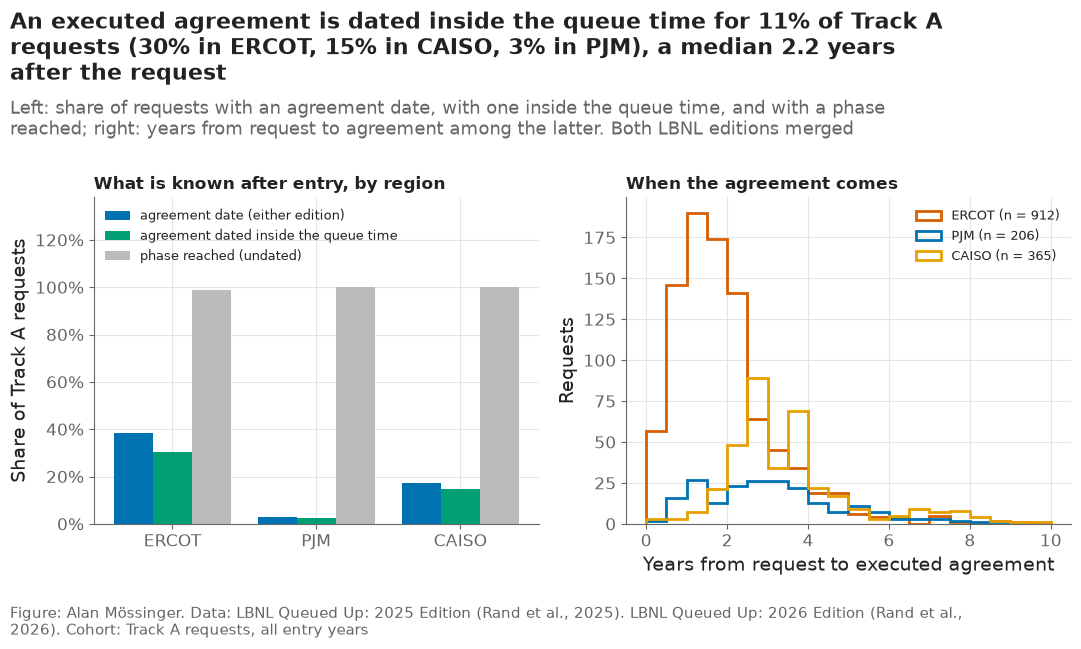

In [7]:
fig, axes = plt.subplots(1, 2)
x = np.arange(len(TRACK_A))
for i, (column, label, color) in enumerate([("agreement_dated", "agreement date (either edition)", "#0072B2"),
                                           ("agreement_inside_queue", "agreement dated inside the queue time", "#009E73"),
                                           ("phase_known", "phase reached (undated)", "#BBBBBB")]):
    axes[0].bar(x + (i - 1) * 0.27, cov.loc[TRACK_A, column], width=0.27, color=color, label=label)
axes[0].set_xticks(x, TRACK_A)
axes[0].yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Share of Track A requests")
axes[0].set_title("What is known after entry, by region", fontsize=12)
axes[0].set_ylim(0, 1.38)  # room for the legend above the 100% bars
axes[0].legend(fontsize=9, loc="upper left")
inside = milestones[milestones["ia_inside_queue"]]
for region in TRACK_A:
    part = inside.loc[inside["region"] == region, "ia_years"]
    axes[1].hist(part, bins=np.arange(0, 10.5, 0.5), histtype="step", linewidth=2, color=plots.region_color(region),
                 label=f"{region} (n = {len(part):,})")
axes[1].set_xlabel("Years from request to executed agreement")
axes[1].set_ylabel("Requests")
axes[1].set_title("When the agreement comes", fontsize=12)
axes[1].legend(fontsize=9)
plots.finish(fig,
             f"An executed agreement is dated inside the queue time for {cov.loc['all', 'agreement_inside_queue']:.0%} of Track A "
             f"requests ({cov.loc['ERCOT', 'agreement_inside_queue']:.0%} in ERCOT, {cov.loc['CAISO', 'agreement_inside_queue']:.0%} "
             f"in CAISO, {cov.loc['PJM', 'agreement_inside_queue']:.0%} in PJM), a median "
             f"{inside['ia_years'].median():.1f} years after the request",
             "Left: share of requests with an agreement date, with one inside the queue time, and with a phase reached; "
             "right: years from request to agreement among the latter. Both LBNL editions merged",
             "Track A requests, all entry years", lbnl_2026=True)
save(fig, "13_01_milestone_coverage", "Coverage of post-entry milestones by region and the timing of executed agreements.")
plt.show()

**Reading this.** The usable landmark is thin and uneven. An agreement dated *inside* the queue time — after the request and before the exit, the only kind a landmark model can condition on — exists for 1,483 requests (11%): 31% of ERCOT's, 15% of CAISO's and 2.6% of PJM's, because the public file carries almost no PJM agreement dates. The median agreement comes 2.2 years after the request, and 45% of requests with one went on to operate (against 8% of all requests), which is the signal notebook 14 will measure at the agreement landmark. For PJM, 59% of Track A, PJM's own export (section 3) carries no study or agreement dates either, so the +12 and +24-month landmarks carry an agreement flag that is nearly always "no or unknown" for PJM, and the notebook says so.

## 5. Checks

In [8]:
checks = pd.DataFrame([
    {"check": "one row per Track A request", "value": len(milestones), "pass": len(milestones) == len(track_a) and milestones["project_key"].is_unique},
    {"check": "no agreement date before the request date is used", "value": int((milestones["ia_inside_queue"] & (milestones["ia_years"] <= 0)).sum()),
     "pass": not (milestones["ia_inside_queue"] & (milestones["ia_years"] <= 0)).any()},
    {"check": "CAISO 2017–2019 entrants found in the ISO report ≥ 70%", "value": round(float(join_rates.loc[0, "share_found_2017_2019"]), 3),
     "pass": bool(join_rates.loc[0, "share_found_2017_2019"] >= 0.70)},
    {"check": "the two editions agree on shared agreement dates (≥ 80% within 90 days)",
     "value": round(float(agreement.loc[f"within {IA_TOLERANCE_DAYS} days", "count"] / max(agreement.loc["in both", "count"], 1)), 3),
     "pass": bool(agreement.loc[f"within {IA_TOLERANCE_DAYS} days", "count"] / max(agreement.loc["in both", "count"], 1) >= 0.80)},
])
checks.to_csv(paths.RESULTS / "milestone_checks.csv", index=False)
assert checks["pass"].all(), checks
checks

,check,value,pass
0,one row per Track A request,13366.000,True
1,no agreement date before the request date is used,0.000,True
2,CAISO 2017–2019 entrants found in the ISO repo...,1.000,True
3,the two editions agree on shared agreement dat...,0.944,True


## Takeaways

- Merging the two LBNL editions dates an executed agreement for 1,818 Track A requests (14%); the editions agree on 94% of shared dates.
- CAISO's own queue report joins 100% of the 2017–2019 LBNL CAISO requests and agrees with the LBNL dates; it adds cluster and agreement status, not phase dates.
- 1,483 requests (11%) have an agreement dated inside their queue time — ERCOT 31%, CAISO 15%, PJM 2.6%; 45% of them operated.
- PJM's queue export (fetched 2026-10-07) agrees with the LBNL PJM dates on the same day for every shared date but dates no study or agreement; ERCOT's GIS report dates every phase but lists none of the test requests that operated or withdrew. Neither adds a dated, outcome-blind landmark; the milestone table is unchanged (decision #57).
- **What goes to the report:** the data section (what is dated after entry, by region); figure 13_01; the agreement-status table as evidence that the agreement is close to a necessary condition for operation.